# Joint decoding MD/HD

**Here's the method I'm using:**

```
def joint_bayesian_decoding(rate_map, spike_counts, tau, hd_bins, md_bins, eps=1e-10):
    """
    For each time bin, compute the Poisson log-likelihood for every (movement direction,
    head direction) bin combination, then choose the bin with the highest posterior probability.
    
    Parameters:
      rate_map     : 3D array (n_md_bins, n_hd_bins, n_neurons) from tuning curves
      spike_counts : 2D array (n_time_bins, n_neurons) of spike counts
      tau          : time bin size (s)
      hd_bins      : array of head-direction bin edges
      md_bins      : array of movement-direction bin edges
      eps          : small constant to avoid log(0)
    
    Returns:
      decoded_hd   : decoded head direction (bin center) for each time bin
      decoded_md   : decoded movement direction (bin center) for each time bin
      posterior_all: list of posterior arrays (one per time bin)
    """
    n_time_bins = spike_counts.shape[0]
    n_md_bins = rate_map.shape[0]
    n_hd_bins = rate_map.shape[1]
    decoded_hd = np.zeros(n_time_bins)
    decoded_md = np.zeros(n_time_bins)
    posterior_all = [] 
    
    # Loop over each time bin
    for t in tqdm(range(n_time_bins), desc="Decoding time bins"):
        # For each (md, hd) combination, compute the log-likelihood.
        # Using a Poisson model: logL = sum_n [ k[t,n]*log(rate_map*tau + eps) - rate_map*tau ]
        # broadcasting: spike_counts[t] has shape (n_neurons,)
        logL = np.nansum(spike_counts[t][None, None, :] * np.log(rate_map * tau + eps) - rate_map * tau, axis=2)
        
        # For numerical stability, subtract the maximum logL before exponentiating.
        max_logL = np.max(logL)
        posterior = np.exp(logL - max_logL)
        posterior = posterior / np.nansum(posterior)  # normalize to sum to 1
        posterior_all.append(posterior)
        
        # Choose the bin with maximum posterior probability
        md_idx, hd_idx = np.unravel_index(np.argmax(posterior), posterior.shape)
        decoded_md[t] = (md_bins[md_idx] + md_bins[md_idx + 1]) / 2
        decoded_hd[t] = (hd_bins[hd_idx] + hd_bins[hd_idx + 1]) / 2

    return decoded_hd, decoded_md, posterior_all
```

## Population decoding analysis

In [3]:
import numpy as np
import os 
import matplotlib.pyplot as plt
from tqdm import tqdm

from pathlib import Path
current_file_path = Path().resolve().parent
current_file_path

PosixPath('/home/mag/variance-analysis')

In [2]:
print("Rat sessions in dataset 6:")
for item in os.listdir(current_file_path / 'data/dusz/Dataset_6'):
    if item[0] == 'A':
        print(item)

Rat sessions in dataset 6:
A1806-190307
A1815-190523
A1110-180619
A1113-180816
A1824-190827
A1804-190104
A1110-180626
A1110-180612
A1801-181015
A1110-180617
A1110-180621
A1806-190314
A1821-190910
A1808-190807
A1113-180813
A1813-190408
A1106-180418
A1801-181004
A1804-181225
A1106-180419
A1110-180613


In [130]:
dataset = 'dusz'
dataset_n = 6
session = 'A1808-190807'

# played around with this smoothing -- the optimal amount of smoothing is different per rat
smoothing = 200

velocity_filter = 5 # cm/s


In [131]:
# create ratemaps, then jointly decode hd & md
os.chdir('..')

! python src/dusz_ratemaps_hd.py --dataset {dataset_n} --rat {session} --smooth_window {smoothing} --vel_threshold {velocity_filter}
! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --smooth_window {smoothing} --vel_threshold {velocity_filter}

#! python src/decode_hd_md_per_neuron.py --dataset {dataset_n} --rat {session} --smooth_window {smoothing} --vel_threshold {velocity_filter}

# dropping 28% at 5 cm/s filter

os.chdir('notebooks')

hd [ 2  4  5  6  7  8 10 15 18 20 23 27 28 29 32 33 34 35 37 38 42 49 52 53
 66 67 72 90 91 96]
excit [ 2  4  5  6  7  8 10 15 18 20 23 27 28 29 31 32 33 34 35 37 38 42 48 49
 52 53 66 67 72 90 91 96 99]
good [ 1  2  3  4  5  6  7  8 10 14 15 18 20 22 23 26 27 28 29 31 32 33 34 35
 37 38 42 43 44 45 47 48 49 50 52 53 55 56 58 62 63 65 66 67 69 72 78 85
 87 90 91 96 99]
fs [ 1  3 14 22 43 55 62 65 69 78 85 87]
excit_not_hd (array([31, 48, 99]),)
7606
Separating spike data by neuron: 100%|██████| 101/101 [00:00<00:00, 2204.47it/s]
# neurons: 33
Computing freq maps: 100%|████████████████████| 33/33 [00:00<00:00, 1903.70it/s]
Unpacking frequency maps...
Dropping 30.92% due to low velocity
Creating rate maps...
Building rate maps (outer loop): 100%|██████████| 17/17 [00:01<00:00, 15.33it/s]
Runtime: 0.07 minutes
Starting joint Bayesian decoding...
Decoding time bins:   0%|                 | 26/7605 [00:00<00:00, 158967.79it/s]
Traceback (most recent call last):
  File "/home/mag/variance-an

In [118]:
import pandas as pd
# second some traj and distribution of movement dir

save_path = current_file_path / f"results/{dataset}/Dataset_{dataset_n}/{session}"
data_path = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data/Tracking_data.csv"

decoded_hd = np.load(f"{save_path}/decoded_hd_17_17.npy")
decoded_md = np.load(f"{save_path}/decoded_md_17_17.npy")
time_centers = np.load(f"{save_path}/time_centers.npy")

tracking_data = pd.read_csv(data_path)

tracking_data.columns = ['timestamp', 'x', 'y', 'hd', 'pitch', 'roll']
positions = tracking_data[['timestamp', 'x', 'y', 'hd']].to_numpy()

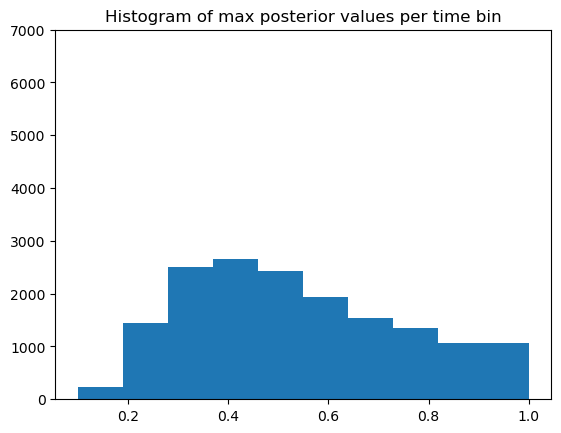

In [119]:
posteriors = np.load(f"{save_path}/posterior_17_17.npy")
max_post = np.max(posteriors, axis=(1,2))

plt.hist(max_post) 
plt.ylim(0, 7000)
plt.title('Histogram of max posterior values per time bin')
plt.show()

In [120]:
# get velocity

from scipy.io import loadmat
from scipy.io.matlab._mio5_params import mat_struct

def extract_matlab_obj(obj):
    """
    Recursively extract MATLAB structs into Python dictionaries and arrays.
    """
    if not (isinstance(obj, mat_struct) or isinstance(obj, dict)):
        return obj

    out = {}
    obj = obj.__dict__ if isinstance(obj, mat_struct) else obj

    for key, val in obj.items():
        # Skip metadata
        if key in ['_fieldnames', 'type', 'time_unit', 'data_unit', 'name']:
            continue

        if isinstance(val, mat_struct) or isinstance(val, dict):
            out[key] = extract_matlab_obj(val)
        elif isinstance(val, np.ndarray):
            arr = []
            for v in val:
                arr.append(extract_matlab_obj(v))
            out[key] = np.array(arr)
        else:
            out[key] = val

    return out


fp = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data/Velocity.mat"
velocity = loadmat(fp, struct_as_record=False, squeeze_me=True)

velocity = extract_matlab_obj(velocity['vel'])
velocity = np.dstack((velocity['t'], velocity['data']))[0]

# extract only the relevant epoch data

epochs_file = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data/BehavEpochs.mat"
epochs = loadmat(epochs_file, struct_as_record=False, squeeze_me=True)
if dataset_n == 6:
    epoch_data = extract_matlab_obj(epochs['wakeEp'])
else:
    epoch_data = extract_matlab_obj(epochs['wake1Ep'])

mask = (velocity[:, 0] > epoch_data['start']) & (velocity[:, 0] < epoch_data['stop'])
velocity = velocity[mask]

position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
positions = positions[position_mask]


print(positions[:10, 0])
print(velocity[:10, 0])

[3044.968 3044.978 3044.988 3044.998 3045.008 3045.018 3045.028 3045.038
 3045.048 3045.058]
[3044.968 3044.978 3044.988 3044.998 3045.008 3045.018 3045.028 3045.038
 3045.048 3045.058]


In [121]:
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd

save_path = current_file_path / f"results/{dataset}/Dataset_{dataset_n}/{session}"
data_path = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data/Tracking_data.csv"

decoded_hd = np.load(f"{save_path}/decoded_hd_17_17.npy")
decoded_md = np.load(f"{save_path}/decoded_md_17_17.npy")
time_centers = np.load(f"{save_path}/time_centers.npy")

tracking_data = pd.read_csv(data_path)

tracking_data.columns = ['timestamp', 'x', 'y', 'hd', 'pitch', 'roll']
positions = tracking_data[['timestamp', 'x', 'y', 'hd']].to_numpy()

posteriors = np.load(f"{save_path}/posterior_17_17.npy")
max_post = np.max(posteriors, axis=(1,2))

#plt.hist(max_post) 
#plt.ylim(0, 7000)
#plt.title('Histogram of max posterior values per time bin')
#plt.show()

# get velocity

from scipy.io import loadmat
from scipy.io.matlab._mio5_params import mat_struct

def extract_matlab_obj(obj):
    """
    Recursively extract MATLAB structs into Python dictionaries and arrays.
    """
    if not (isinstance(obj, mat_struct) or isinstance(obj, dict)):
        return obj

    out = {}
    obj = obj.__dict__ if isinstance(obj, mat_struct) else obj

    for key, val in obj.items():
        # Skip metadata
        if key in ['_fieldnames', 'type', 'time_unit', 'data_unit', 'name']:
            continue

        if isinstance(val, mat_struct) or isinstance(val, dict):
            out[key] = extract_matlab_obj(val)
        elif isinstance(val, np.ndarray):
            arr = []
            for v in val:
                arr.append(extract_matlab_obj(v))
            out[key] = np.array(arr)
        else:
            out[key] = val

    return out


fp = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data/Velocity.mat"
velocity = loadmat(fp, struct_as_record=False, squeeze_me=True)

velocity = extract_matlab_obj(velocity['vel'])
velocity = np.dstack((velocity['t'], velocity['data']))[0]

# extract only the relevant epoch data

epochs_file = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data/BehavEpochs.mat"
epochs = loadmat(epochs_file, struct_as_record=False, squeeze_me=True)
if dataset_n == 6:
    epoch_data = extract_matlab_obj(epochs['wakeEp'])
else:
    epoch_data = extract_matlab_obj(epochs['wake1Ep'])

mask = (velocity[:, 0] > epoch_data['start']) & (velocity[:, 0] < epoch_data['stop'])
velocity = velocity[mask]

position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
positions = positions[position_mask]


#print(positions[:10, 0])
#print(velocity[:10, 0])

# TODO load this in from an actual class in the future
def get_md_from_xy(positions, smoothing_window=75):
    def rolling_mean(positions):
        kernel = np.ones(smoothing_window) / smoothing_window
        return np.convolve(positions, kernel, mode='same')

    def circular_smooth(angles, smoothing_window=5):
        angles_rad = np.radians(angles)
        
        sin_vals = np.sin(angles_rad)
        cos_vals = np.cos(angles_rad)
        
        kernel = np.ones(smoothing_window) / smoothing_window
        
        smooth_sin = np.convolve(sin_vals, kernel, mode='same')
        smooth_cos = np.convolve(cos_vals, kernel, mode='same')
        
        smooth_angles = np.degrees(np.arctan2(smooth_sin, smooth_cos)) % 360
        return smooth_angles
        
    #x = rolling_mean(positions[:, 1])
    #y = rolling_mean(positions[:, 2])

    x = positions[:, 1]
    y = positions[:, 2]
    
    dx = x[1:] - x[:-1]
    dy = y[1:] - y[:-1]

    direction = np.degrees(np.arctan2(dy, dx))
    direction = (direction + 360) % 360
    direction = circular_smooth(direction, smoothing_window=smoothing_window)

    direction = np.concatenate([direction, [direction[-1]]])

    return direction


# --- Calculate ground truth movement direction using positional info ---
ground_md = get_md_from_xy(positions, smoothing_window=smoothing)

# --- Interpolate ground truth values to the time bin centers ---
timestamps = positions[:, 0]
ground_hd_interp = (np.interp(time_centers, timestamps, positions[:, 3]) + 360) % 360
ground_md_interp = np.interp(time_centers, timestamps, ground_md)
velocity_interp = np.interp(time_centers, velocity[:, 0], velocity[:, 1])

# --- Apply velocity filtering ---
# Define your velocity threshold (in cm/s)
vel_threshold = velocity_filter

# Create a mask for time bins where the velocity meets the threshold.
valid_mask = velocity_interp >= vel_threshold

# Set values to NaN when velocity is below threshold.
ground_hd_interp_filtered = np.where(valid_mask, ground_hd_interp, np.nan)
ground_md_interp_filtered = np.where(valid_mask, ground_md_interp, np.nan)
decoded_hd_filtered       = np.where(valid_mask, decoded_hd, np.nan)
decoded_md_filtered       = np.where(valid_mask, decoded_md, np.nan)
velocity_filtered         = np.where(valid_mask, velocity_interp, np.nan)

def circular_difference(decoded, ground_truth):
    diff = (decoded - ground_truth + 180) % 360 - 180
    return diff

hd_error = circular_difference(decoded_hd, ground_hd_interp)
md_error = circular_difference(decoded_md, ground_md_interp)

mean_abs_hd_error = np.nanmean(np.abs(hd_error))
median_hd_error = np.nanmedian(np.abs(hd_error))
mean_abs_md_error = np.nanmean(np.abs(md_error))
median_md_error = np.nanmedian(np.abs(md_error))

print("Head Direction Mean Absolute Error: {:.2f}°".format(mean_abs_hd_error))
print("Head Direction Median Error: {:.2f}°".format(median_hd_error))
print("Movement Direction Mean Absolute Error: {:.2f}°".format(mean_abs_md_error))
print("Movement Direction Median Error: {:.2f}°".format(median_md_error))

# --- Plotting the results ---
# Define which portion of the time series to plot
time_min = 200
time_max = 400

plot_vel = False

fig, axs = plt.subplots(2, 2, figsize=(12, 8))

# Real head direction subplot (top left)
ax0 = axs[0, 0]
ax0.scatter(time_centers[time_min:time_max], ground_hd_interp_filtered[time_min:time_max], label="Real HD")
ax0.set_title("Real Head Direction")
ax0.set_xlabel("Time (s)")
ax0.set_ylabel("Head Direction (°)")
ax0.set_ylim(-10, 370)
# Secondary y-axis for velocity
if plot_vel:
    ax0_vel = ax0.twinx()
    ax0_vel.plot(time_centers[time_min:time_max], velocity_filtered[time_min:time_max], label="Velocity", color="red")
    ax0_vel.set_ylabel("Velocity (cm/s)")
    ax0_vel.set_ylim(0, 15)
    lines1, labels1 = ax0.get_legend_handles_labels()
    lines2, labels2 = ax0_vel.get_legend_handles_labels()
    ax0.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

# Decoded head direction subplot (top right)
ax1 = axs[0, 1]
ax1.scatter(time_centers[time_min:time_max], decoded_hd_filtered[time_min:time_max], label="Decoded HD", color="orange")
ax1.set_title("Decoded Head Direction")
ax1.set_xlabel("Time (s)")
ax1.set_ylabel("Head Direction (°)")
ax1.set_ylim(-10, 370)
if plot_vel:
    ax1_vel = ax1.twinx()
    ax1_vel.scatter(time_centers[time_min:time_max], velocity_filtered[time_min:time_max], label="Velocity", color="red")
    ax1_vel.set_ylabel("Velocity (cm/s)")
    ax1_vel.set_ylim(0, 15)
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax1_vel.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

# Real movement direction subplot (bottom left)
ax2 = axs[1, 0]
ax2.scatter(time_centers[time_min:time_max], ground_md_interp_filtered[time_min:time_max], label="Real MD")
ax2.set_title("Real Movement Direction")
ax2.set_xlabel("Time (s)")
ax2.set_ylabel("Movement Direction (°)")
ax2.set_ylim(-10, 370)
if plot_vel:
    ax2_vel = ax2.twinx()
    ax2_vel.scatter(time_centers[time_min:time_max], velocity_filtered[time_min:time_max], label="Velocity", color="red")
    ax2_vel.set_ylabel("Velocity (cm/s)")
    ax2_vel.set_ylim(0, 15)
    lines1, labels1 = ax2.get_legend_handles_labels()
    lines2, labels2 = ax2_vel.get_legend_handles_labels()
    ax2.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

# Decoded movement direction subplot (bottom right)
ax3 = axs[1, 1]
ax3.scatter(time_centers[time_min:time_max], decoded_md_filtered[time_min:time_max], label="Decoded MD", color="green")
ax3.set_title("Decoded Movement Direction")
ax3.set_xlabel("Time (s)")
ax3.set_ylabel("Movement Direction (°)")
ax3.set_ylim(-10, 370)
if plot_vel:
    ax3_vel = ax3.twinx()
    ax3_vel.scatter(time_centers[time_min:time_max], velocity_filtered[time_min:time_max], label="Velocity", color="red")
    ax3_vel.set_ylabel("Velocity (cm/s)")
    ax3_vel.set_ylim(0, 15)
    lines1, labels1 = ax3.get_legend_handles_labels()
    lines2, labels2 = ax3_vel.get_legend_handles_labels()
    ax3.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

plt.tight_layout()
plt.show()


ValueError: operands could not be broadcast together with shapes (5640,) (22559,) () 

In [8]:
# how much are the two correlated?

diff_md = ground_md_interp[1:] - ground_md_interp[:-1]
diff_md = np.concatenate([diff_md, [diff_md[-1]]])
correlation_matrix = np.corrcoef(velocity_interp, diff_md)

correlation_matrix


array([[ 1.        , -0.00759899],
       [-0.00759899,  1.        ]])

Head Direction Mean Absolute Error: 13.22°
Head Direction Median Error: 9.31°
Movement Direction Mean Absolute Error: 61.09°
Movement Direction Median Error: 44.28°


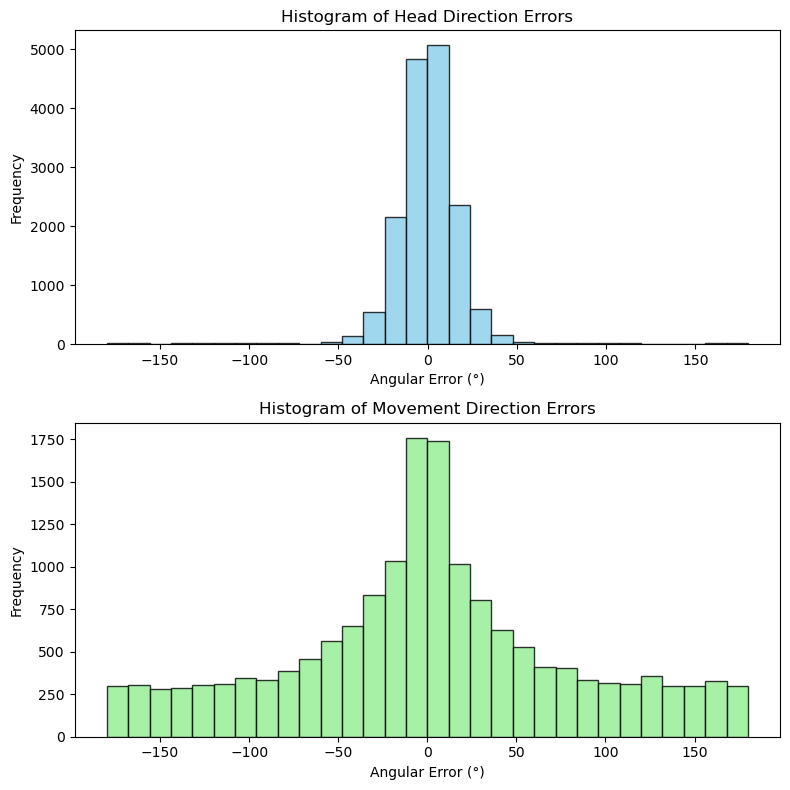

'\n8 vel filtering:\nHead Direction Mean Absolute Error: 13.48°\nHead Direction Median Error: 9.31°\nMovement Direction Mean Absolute Error: 57.84°\nMovement Direction Median Error: 41.23°\n\n2 vel filtering: \nHead Direction Mean Absolute Error: 13.96°\nHead Direction Median Error: 9.35°\nMovement Direction Mean Absolute Error: 64.06°\nMovement Direction Median Error: 48.85°\n\n0 vel filtering (loading):\n\n\n'

In [9]:
import numpy as np
import matplotlib.pyplot as plt

def circular_difference(decoded, ground_truth):
    diff = (decoded - ground_truth + 180) % 360 - 180
    return diff

hd_error = circular_difference(decoded_hd, ground_hd_interp)
md_error = circular_difference(decoded_md, ground_md_interp)

mean_abs_hd_error = np.nanmean(np.abs(hd_error))
median_hd_error = np.nanmedian(np.abs(hd_error))
mean_abs_md_error = np.nanmean(np.abs(md_error))
median_md_error = np.nanmedian(np.abs(md_error))

print("Head Direction Mean Absolute Error: {:.2f}°".format(mean_abs_hd_error))
print("Head Direction Median Error: {:.2f}°".format(median_hd_error))
print("Movement Direction Mean Absolute Error: {:.2f}°".format(mean_abs_md_error))
print("Movement Direction Median Error: {:.2f}°".format(median_md_error))

fig, axs = plt.subplots(2, 1, figsize=(8, 8))

axs[0].hist(hd_error, bins=30, color='skyblue', edgecolor='black', alpha=0.8)
axs[0].set_title("Histogram of Head Direction Errors")
axs[0].set_xlabel("Angular Error (°)")
axs[0].set_ylabel("Frequency")

axs[1].hist(md_error, bins=30, color='lightgreen', edgecolor='black', alpha=0.8)
axs[1].set_title("Histogram of Movement Direction Errors")
axs[1].set_xlabel("Angular Error (°)")
axs[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

'''
8 vel filtering:
Head Direction Mean Absolute Error: 13.48°
Head Direction Median Error: 9.31°
Movement Direction Mean Absolute Error: 57.84°
Movement Direction Median Error: 41.23°

2 vel filtering: 
Head Direction Mean Absolute Error: 13.96°
Head Direction Median Error: 9.35°
Movement Direction Mean Absolute Error: 64.06°
Movement Direction Median Error: 48.85°

0 vel filtering (loading):


'''

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

def circular_difference(decoded, ground_truth):
    diff = (decoded - ground_truth + 180) % 360 - 180
    return diff

# Compute centered errors for head direction (HD) and movement direction (MD)
hd_error = circular_difference(decoded_hd, ground_hd_interp)
md_error = circular_difference(decoded_md, ground_md_interp)

# (Optional) Compute individual error statistics
mean_abs_hd_error = np.nanmean(np.abs(hd_error))
median_hd_error = np.nanmedian(np.abs(hd_error))
mean_abs_md_error = np.nanmean(np.abs(md_error))
median_md_error = np.nanmedian(np.abs(md_error))

print("Head Direction Mean Absolute Error: {:.2f}°".format(mean_abs_hd_error))
print("Head Direction Median Error: {:.2f}°".format(median_hd_error))
print("Movement Direction Mean Absolute Error: {:.2f}°".format(mean_abs_md_error))
print("Movement Direction Median Error: {:.2f}°".format(median_md_error))

# Joint decoding: Combine errors into a 2D array
errors = np.vstack((hd_error, md_error))

# Create a scatter plot of the centered errors
plt.figure(figsize=(8, 8))
plt.scatter(hd_error, md_error, alpha=0.6, label='Error points')
plt.xlabel('Head Direction Error (°)')
plt.ylabel('Movement Direction Error (°)')
plt.title('Joint Decoding Errors: Centered 2D Scatter Plot')

# Fit a 2D Gaussian: compute mean and covariance of the errors
mean = np.nanmean(errors, axis=1)  # Mean vector of [HD_error, MD_error]
import numpy.ma as ma
cov = ma.cov(ma.masked_invalid(errors), rowvar=False)
#cov = np.cov(errors)            # Covariance matrix

# Eigen-decomposition to get the ellipse parameters
eigvals, eigvecs = np.linalg.eig(cov)
# Compute the angle of the ellipse (in degrees)
angle = np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0]))
# For a 1-sigma ellipse, width and height are 2*sqrt(eigenvalues)
width, height = 2 * np.sqrt(eigvals[0]), 2 * np.sqrt(eigvals[1])

# Plot the 1-sigma ellipse representing the 2D Gaussian fit
ellipse = patches.Ellipse(xy=mean, width=width, height=height, angle=angle,
                          edgecolor='red', fc='None', lw=2, label='1σ Ellipse')
plt.gca().add_patch(ellipse)

plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()


Head Direction Mean Absolute Error: 13.22°
Head Direction Median Error: 9.31°
Movement Direction Mean Absolute Error: 61.09°
Movement Direction Median Error: 44.28°



KeyboardInterrupt



Error in callback <function flush_figures at 0x7f366992c360> (for post_execute), with arguments args (),kwargs {}:



KeyboardInterrupt



### Find the best smoothing factor for this session (optional)

I'm smoothing the head direction estimate over time to reduce noise. The rat's position is sampled at 100Hz, so a smoothing window of 100 means sampling the mean movement direction per second.

In [16]:
import numpy as np
import os
import matplotlib.pyplot as plt
from tqdm import tqdm
import pandas as pd
from pathlib import Path

current_file_path = Path().resolve().parent
dataset = 'dusz'
dataset_n = 6
session = 'A1813-190408'

best_smoothing = None
best_joint_error = np.inf
error_results = []

# cross validate the decoding and consider a smaller smoothing window, even 30 might be too big if it's 10 ms
# the pattern with the smoothing window is actually interesting
# histogram with different time windows
# probably more like a 30 ms smoothing window
# maybe a gaussian fit linear regression to calculate movement direction
# maybe just do both and see if there's a major difference -> current method for smoothing is probably okay
# plot a histogram estimate of md, need an estimate of how much the rat is moving per timestep
# plot a few different versions of the traj plot for md

for smoothing in tqdm(range(1, 100, 10)):
    print(f"\nProcessing smoothing window: {smoothing}")
    
    os.chdir('..')
    os.system(f"python src/dusz_ratemaps_hd.py --dataset {dataset_n} --rat {session} --smooth_window {smoothing}")
    os.system(f"python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --smooth_window {smoothing}")
    
    os.chdir('notebooks')
    
    save_path = current_file_path / f"results/{dataset}/Dataset_{dataset_n}/{session}"
    data_path = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data/Tracking_data.csv"
    
    decoded_hd = np.load(f"{save_path}/decoded_hd_17_17.npy")
    decoded_md = np.load(f"{save_path}/decoded_md_17_17.npy")
    time_centers = np.load(f"{save_path}/time_centers.npy")
    
    tracking_data = pd.read_csv(data_path)
    tracking_data.columns = ['timestamp', 'x', 'y', 'hd', 'pitch', 'roll']
    positions = tracking_data[['timestamp', 'x', 'y', 'hd']].to_numpy()
    
    def get_md_from_xy(positions, smoothing_window):
        def rolling_mean(pos):
            kernel = np.ones(smoothing_window) / smoothing_window
            return np.convolve(pos, kernel, mode='same')
        x = rolling_mean(positions[:, 1])
        y = rolling_mean(positions[:, 2])
        dx = np.diff(x, prepend=x[0])
        dy = np.diff(y, prepend=y[0])
        md = np.degrees(np.arctan2(dy, dx))
        md = (md + 360) % 360
        return md
    
    ground_md = get_md_from_xy(positions, smoothing_window=smoothing)
    
    timestamps = positions[:, 0]
    ground_hd_interp = np.interp(time_centers, timestamps, positions[:, 3])
    ground_md_interp = np.interp(time_centers, timestamps, ground_md)
    
    def circular_difference(decoded, ground_truth):
        diff = (decoded - ground_truth + 180) % 360 - 180
        return diff
    
    hd_error = circular_difference(decoded_hd, ground_hd_interp)
    md_error = circular_difference(decoded_md, ground_md_interp)
    
    median_hd_error = np.median(np.abs(hd_error))
    median_md_error = np.median(np.abs(md_error))
    
    joint_error = median_hd_error + median_md_error
    error_results.append((smoothing, median_hd_error, median_md_error, joint_error))
    
    print(f"Smoothing: {smoothing} | Median HD Error: {median_hd_error:.2f}° | "
          f"Median MD Error: {median_md_error:.2f}° | Joint Error: {joint_error:.2f}°")
    
    if joint_error < best_joint_error:
        best_joint_error = joint_error
        best_smoothing = smoothing

print("\nBest smoothing window value:", best_smoothing)
print("Error metrics (smoothing, median hd error, median md error, joint error):")
for res in error_results:
    print(f"Smoothing: {res[0]} | Median HD Error: {res[1]:.2f}° | "
          f"Median MD Error: {res[2]:.2f}° | Joint Error: {res[3]:.2f}°")


  0%|                                                    | 0/10 [00:00<?, ?it/s]


Processing smoothing window: 1
hd (array([ 1,  3,  8, 13, 14, 15, 16, 17, 22, 23, 24, 26, 29, 30, 32, 33, 34,
       35, 38, 39, 40, 43, 49, 57, 63, 64, 67]),)
excit (array([ 1,  3,  6,  8,  9, 13, 14, 15, 16, 17, 22, 23, 24, 26, 27, 29, 30,
       32, 33, 34, 35, 38, 39, 40, 43, 49, 52, 57, 63, 64, 67]),)
good (array([ 1,  2,  3,  5,  6,  8,  9, 10, 11, 13, 14, 15, 16, 17, 19, 22, 23,
       24, 26, 27, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 42, 43,
       44, 46, 48, 49, 50, 51, 52, 53, 54, 56, 57, 59, 60, 61, 62, 63, 64,
       65, 66, 67, 69]),)
fs (array([ 2, 10, 11, 19, 36, 48, 51, 53, 54, 56, 59, 60, 61, 62, 65, 66]),)
excit_not_hd (array([ 6,  9, 27, 52]),)
# neurons: 70


Computing freq maps: 100%|██████████| 70/70 [00:00<00:00, 196.98it/s]


Unpacking frequency maps...
Creating rate maps...


Building rate maps (outer loop): 100%|██████████| 17/17 [00:01<00:00, 12.82it/s]


...

Runtime: 0.05 minutes
Starting joint Bayesian decoding...


Decoding time bins: 100%|██████████| 8684/8684 [00:00<00:00, 9375.94it/s]


Decoding completed in 0.93 seconds
Decoded results saved to /home/mag/variance-analysis/results/dusz/Dataset_6/A1813-190408


100%|███████████████████████████████████████████| 10/10 [02:22<00:00, 14.23s/it]

Smoothing: 91 | Median HD Error: 9.31° | Median MD Error: 52.16° | Joint Error: 61.47°

Best smoothing window value: 81
Error metrics (smoothing, median hd error, median md error, joint error):
Smoothing: 1 | Median HD Error: 9.36° | Median MD Error: 69.44° | Joint Error: 78.80°
Smoothing: 11 | Median HD Error: 9.31° | Median MD Error: 61.18° | Joint Error: 70.49°
Smoothing: 21 | Median HD Error: 9.31° | Median MD Error: 57.67° | Joint Error: 66.98°
Smoothing: 31 | Median HD Error: 9.30° | Median MD Error: 56.32° | Joint Error: 65.62°
Smoothing: 41 | Median HD Error: 9.38° | Median MD Error: 52.94° | Joint Error: 62.32°
Smoothing: 51 | Median HD Error: 9.28° | Median MD Error: 52.61° | Joint Error: 61.89°
Smoothing: 61 | Median HD Error: 9.38° | Median MD Error: 52.97° | Joint Error: 62.36°
Smoothing: 71 | Median HD Error: 9.18° | Median MD Error: 51.86° | Joint Error: 61.04°
Smoothing: 81 | Median HD Error: 9.28° | Median MD Error: 51.44° | Joint Error: 60.72°
Smoothing: 91 | Median H

## Per-neuron decoding analysis

In [90]:
dataset = 'dusz'
dataset_n = 6
session = 'A1821-190910'

smoothing = 290

In [116]:
# optionally run the script from scratch
# only works for dusz datasets right now
os.chdir('..')

#! python src/dusz_ratemaps_hd_cv.py --dataset {dataset_n} --rat {session} --smooth_window {smoothing} --vel_threshold 2 #{vel_threshold}
! python src/decode_hd_md_per_neuron.py --dataset {dataset_n} --rat {session} --smooth_window {smoothing} --vel_threshold {vel_threshold} --cv_index 0

os.chdir('notebooks')

total neurons 74
Starting joint Bayesian decoding...
Decoding time bins (per neuron): 100%|████| 5640/5640 [00:00<00:00, 9153.60it/s]
Decoding completed in 0.62 seconds


### Load the rate maps and do variance calculations

In [54]:
def quantify_variance(heatmap_test, heatmap_train, axis=0, verbose=False):
    """
    Quantify the variance due to a certain variable in a cross-validated manner.
    heatmaps are 2D, and are average spikes/sec across visits to each behavioral bin.
    Negative values indicate dominance of inherent variance over dimension-explained variance.
    """

    test_mean = np.nanmean(heatmap_test, axis=axis)
    train_mean = np.nanmean(heatmap_train, axis=axis)

    # Expand along `axis` so we can subtract
    if axis == 0:
        test_mean_expanded = test_mean[np.newaxis, :]
        train_mean_expanded = train_mean[np.newaxis, :]
    else:
        test_mean_expanded = test_mean[:, np.newaxis]
        train_mean_expanded = train_mean[:, np.newaxis]

    n_bins = heatmap_test.shape[axis]

    # Now compute the variance terms with occupancy weighting
    inter_var_test = np.nansum((heatmap_test - test_mean_expanded)**2)
    inter_var_train = np.nansum((heatmap_train - train_mean_expanded)**2)

    intra_var_all = np.nansum((heatmap_test - heatmap_train)**2)
    intra_var_means = n_bins * np.nansum((test_mean - train_mean)**2)

    if verbose:
        print(f"axis={axis} sum((test - test_mean)^2)={inter_var_test:.4f}")
        print(f"axis={axis} sum((train - train_mean)^2)={inter_var_train:.4f}")
        print(f"axis={axis} sum((test - train)^2)={intra_var_all:.4f}")
        print(f"axis={axis} n_bins * sum((test_mean - train_mean)^2)={intra_var_means:.4f}")
        print()
    
    estimator = 0.5 * (
        inter_var_test +
        inter_var_train -
        intra_var_all +
        intra_var_means
    )
    
    return estimator, inter_var_test, inter_var_train, intra_var_all, intra_var_means

In [55]:
hd_rate_map_test = np.load(current_file_path / f'results/{dataset}/Dataset_{dataset_n}/{session}/hd_md_rate_map_fold0_17_17.npy')
hd_rate_map_train = np.load(current_file_path / f'results/{dataset}/Dataset_{dataset_n}/{session}/hd_md_rate_map_fold1_17_17.npy')

n_neurons = hd_rate_map_test.shape[2]

hd_results = np.zeros(n_neurons)
md_results = np.zeros(n_neurons)

for i in range(n_neurons):
    md_results[i] = quantify_variance(hd_rate_map_test[:, :, i], hd_rate_map_train[:, :, i], axis=0, verbose=False)[0]
    hd_results[i] = quantify_variance(hd_rate_map_test[:, :, i], hd_rate_map_train[:, :, i], axis=1, verbose=False)[0]

print('mean hd var:', np.mean(hd_results))
print('mean md var:', np.mean(md_results))


mean hd var: 15781.642664745465
mean md var: 6641.925153572644


In [31]:
n_neurons

6

In [16]:
import pandas as pd

save_path = current_file_path / f"results/{dataset}/Dataset_{dataset_n}/{session}"
data_path = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data/Tracking_data.csv"

decoded_hd = np.load(f"{save_path}/decoded_hd_per_neuron_17_17.npy")
decoded_md = np.load(f"{save_path}/decoded_md_per_neuron_17_17.npy")
time_centers = np.load(f"{save_path}/time_centers.npy")

tracking_data = pd.read_csv(data_path)

tracking_data.columns = ['timestamp', 'x', 'y', 'hd', 'pitch', 'roll']
positions = tracking_data[['timestamp', 'x', 'y', 'hd']].to_numpy()

In [17]:
def get_md_from_xy(positions, smoothing_window=470):
    def rolling_mean(pos):
        kernel = np.ones(smoothing_window) / smoothing_window
        return np.convolve(pos, kernel, mode='same')
    x = rolling_mean(positions[:, 1])
    y = rolling_mean(positions[:, 2])
    dx = np.diff(x, prepend=x[0])
    dy = np.diff(y, prepend=y[0])
    md = np.degrees(np.arctan2(dy, dx))
    md = (md + 360) % 360
    return md

ground_md = get_md_from_xy(positions, smoothing_window=smoothing)

# --- Interpolate ground truth values to the time bin centers ---
timestamps = positions[:, 0]
ground_hd_interp = (np.interp(time_centers, timestamps, positions[:, 3]) + 360) % 360
ground_md_interp = np.interp(time_centers, timestamps, ground_md)

Head Direction Mean Absolute Error: 84.90°
Head Direction Median Error: 82.65°
Movement Direction Mean Absolute Error: 87.94°
Movement Direction Median Error: 87.04°


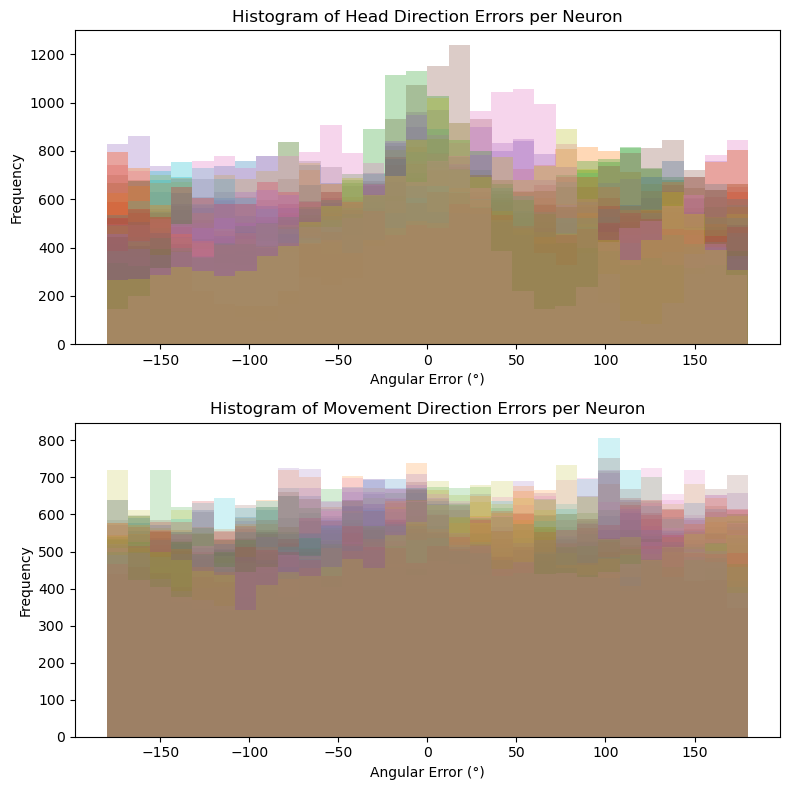

In [19]:

def circular_difference(decoded, ground_truth):
    diff = (decoded - ground_truth + 180) % 360 - 180
    return diff

if ground_hd_interp.ndim == 1:
    ground_hd_interp = ground_hd_interp[:, None]
if ground_md_interp.ndim == 1:
    ground_md_interp = ground_md_interp[:, None]

hd_error = circular_difference(decoded_hd, ground_hd_interp)
md_error = circular_difference(decoded_md, ground_md_interp)

mean_abs_hd_error = np.nanmean(np.abs(hd_error))
median_hd_error = np.nanmedian(np.abs(hd_error))
mean_abs_md_error = np.nanmean(np.abs(md_error))
median_md_error = np.nanmedian(np.abs(md_error))

print("Head Direction Mean Absolute Error: {:.2f}°".format(mean_abs_hd_error))
print("Head Direction Median Error: {:.2f}°".format(median_hd_error))
print("Movement Direction Mean Absolute Error: {:.2f}°".format(mean_abs_md_error))
print("Movement Direction Median Error: {:.2f}°".format(median_md_error))

n_neurons = decoded_hd.shape[1]

fig, axs = plt.subplots(2, 1, figsize=(8, 8))


all_neurons = list(range(1, n_neurons))

selected_neurons = hd #all_neurons

for neuron in selected_neurons:
    axs[0].hist(hd_error[:, neuron], bins=30, alpha=0.3, label=f'Neuron {neuron}, var={hd_results[neuron]:.2f}')
axs[0].set_title("Histogram of Head Direction Errors per Neuron")
axs[0].set_xlabel("Angular Error (°)")
axs[0].set_ylabel("Frequency")
#axs[0].legend()

for neuron in selected_neurons:
    axs[1].hist(md_error[:, neuron], bins=30, alpha=0.2, label=f'Neuron {neuron}, var={md_results[neuron]:.2f}')
axs[1].set_title("Histogram of Movement Direction Errors per Neuron")
axs[1].set_xlabel("Angular Error (°)")
axs[1].set_ylabel("Frequency")
#axs[1].legend()

plt.tight_layout()
plt.show()


In [23]:
np.argsort(md_results / (md_results + hd_results))


array([26, 40, 35, 51, 54, 12, 21, 25, 67,  2, 43, 29, 22,  0, 42, 55, 30,
       16, 33, 69, 14,  8, 66, 68, 36,  1, 49,  4, 56, 53, 64, 44,  5, 20,
       58, 45, 50, 27, 24, 47, 62, 37, 18, 17, 65, 46,  3, 11, 60, 52, 57,
       41,  6, 10, 13, 38, 19, 15,  7, 34, 63, 61, 59, 23,  9, 28, 32, 39,
       48, 31])

Head Direction Mean Absolute Error: 76.50°
Head Direction Median Error: 69.01°
Movement Direction Mean Absolute Error: 92.35°
Movement Direction Median Error: 93.33°


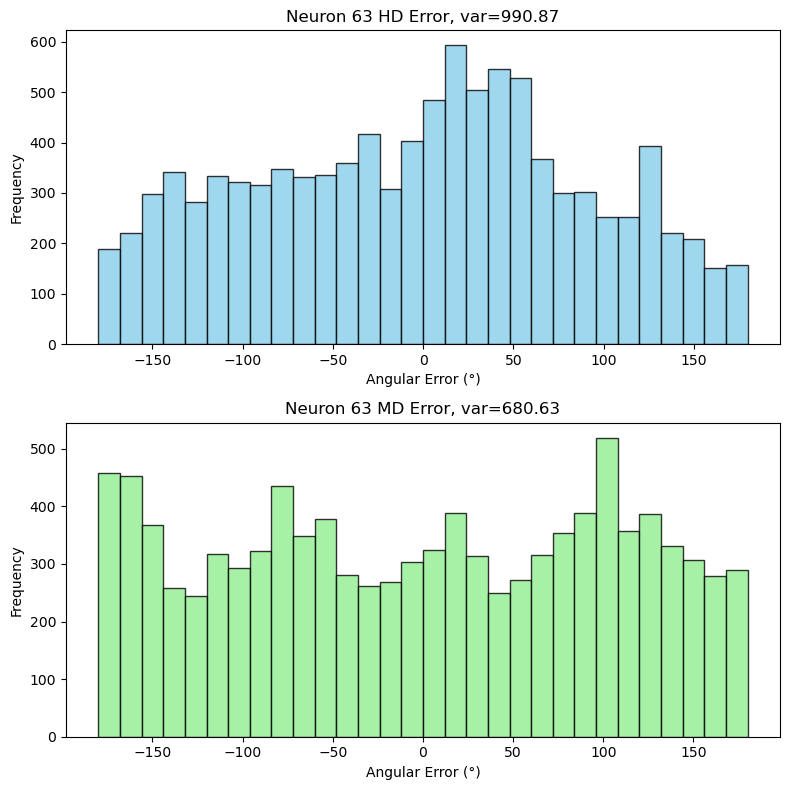

In [32]:
idx = 63

mean_abs_hd_error = np.mean(np.abs(hd_error[:, idx]))
median_hd_error = np.median(np.abs(hd_error[:, idx]))
mean_abs_md_error = np.mean(np.abs(md_error[:, idx]))
median_md_error = np.median(np.abs(md_error[:, idx]))

print("Head Direction Mean Absolute Error: {:.2f}°".format(mean_abs_hd_error))
print("Head Direction Median Error: {:.2f}°".format(median_hd_error))
print("Movement Direction Mean Absolute Error: {:.2f}°".format(mean_abs_md_error))
print("Movement Direction Median Error: {:.2f}°".format(median_md_error))

fig, axs = plt.subplots(2, 1, figsize=(8, 8))

axs[0].hist(hd_error[:, idx], bins=30, color='skyblue', edgecolor='black', alpha=0.8)
axs[0].set_title(f"Neuron {idx} HD Error, var={hd_results[idx]:.2f}")
axs[0].set_xlabel("Angular Error (°)")
axs[0].set_ylabel("Frequency")

axs[1].hist(md_error[:, idx], bins=30, color='lightgreen', edgecolor='black', alpha=0.8)
axs[1].set_title(f"Neuron {idx} MD Error, var={md_results[idx]:.2f}")
axs[1].set_xlabel("Angular Error (°)")
axs[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

In [173]:
# 62 is a good md neuron for the current session
session

# to tell if those artifacts in md, you compute the average error per head direction E[theta] - theta, then you can plot the bias against hp, and if it's sinusoidal then it's real 



'A1813-190408'

Head Direction Mean Absolute Error: 87.83°
Head Direction Median Error: 82.39°
Movement Direction Mean Absolute Error: 92.43°
Movement Direction Median Error: 94.44°


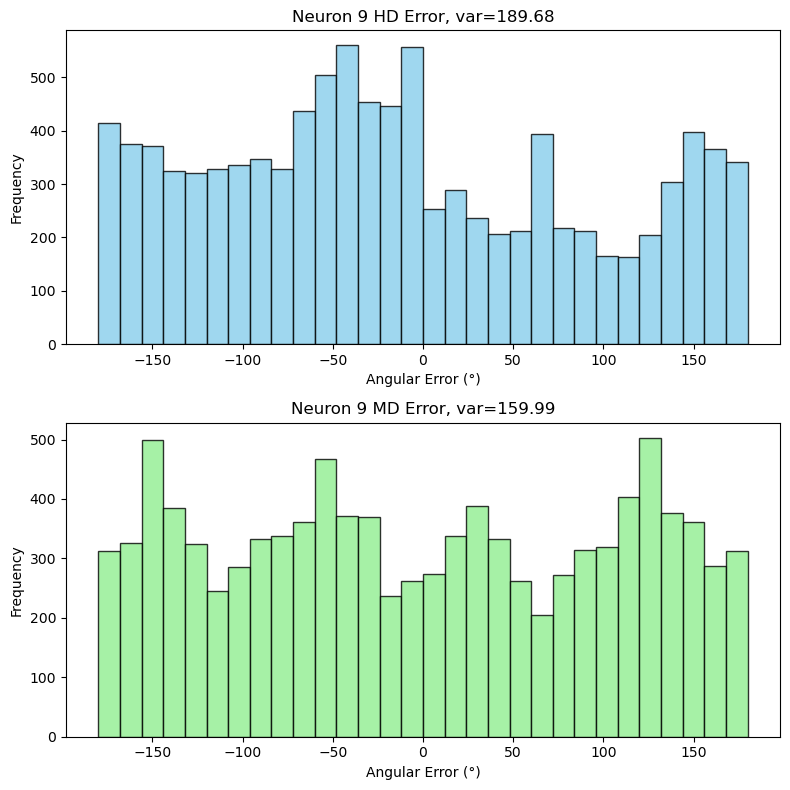

In [30]:
idx = 9

mean_abs_hd_error = np.mean(np.abs(hd_error[:, idx]))
median_hd_error = np.median(np.abs(hd_error[:, idx]))
mean_abs_md_error = np.mean(np.abs(md_error[:, idx]))
median_md_error = np.median(np.abs(md_error[:, idx]))

print("Head Direction Mean Absolute Error: {:.2f}°".format(mean_abs_hd_error))
print("Head Direction Median Error: {:.2f}°".format(median_hd_error))
print("Movement Direction Mean Absolute Error: {:.2f}°".format(mean_abs_md_error))
print("Movement Direction Median Error: {:.2f}°".format(median_md_error))

fig, axs = plt.subplots(2, 1, figsize=(8, 8))

axs[0].hist(hd_error[:, idx], bins=30, color='skyblue', edgecolor='black', alpha=0.8)
axs[0].set_title(f"Neuron {idx} HD Error, var={hd_results[idx]:.2f}")
axs[0].set_xlabel("Angular Error (°)")
axs[0].set_ylabel("Frequency")

axs[1].hist(md_error[:, idx], bins=30, color='lightgreen', edgecolor='black', alpha=0.8)
axs[1].set_title(f"Neuron {idx} MD Error, var={md_results[idx]:.2f}")
axs[1].set_xlabel("Angular Error (°)")
axs[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

## All-out decoding with cross-validation

In [4]:
dataset = 'dusz'
dataset_n = 6
session = 'A1110-180621'

# played around with this smoothing -- the optimal amount of smoothing is different per rat
smoothing = 200

velocity_filter = 5 # cm/s


In [5]:
# create ratemaps, then jointly decode hd & md
os.chdir('..')

! python src/dusz_ratemaps_hd_cv.py --dataset {dataset_n} --rat {session} --smooth_window {smoothing} --vel_threshold {velocity_filter}
! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --smooth_window {smoothing} --vel_threshold {velocity_filter} --cv_index 0 
! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --smooth_window {smoothing} --vel_threshold {velocity_filter} --cv_index 1 
! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --smooth_window {smoothing} --vel_threshold {velocity_filter} --cv_index 2 
! python src/decode_hd_md.py --dataset {dataset_n} --rat {session} --smooth_window {smoothing} --vel_threshold {velocity_filter} --cv_index 3 

# dropping 28% at 5 cm/s filter

os.chdir('notebooks')

hd [ 2  3  4  5  6  7  8  9 10 11 12]
excit [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22]
good [ 0  1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22]
fs []
excit_not_hd (array([ 0,  1, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22]),)
Separating spike data by neuron: 100%|████████| 23/23 [00:00<00:00, 1065.17it/s]
# neurons: 23
Computing freq maps: 100%|██████████████████████| 23/23 [00:08<00:00,  2.57it/s]
Finished computing frequency maps.
Dropping 12.92% of time bins due to low velocity
Creating CV rate maps...
HD bins:   0%|                                           | 0/17 [00:00<?, ?it/s]/home/mag/variance-analysis/src/dusz_ratemaps_hd_cv.py:187: RuntimeWarning: Mean of empty slice
  global_test_rate = np.nanmean(freq_maps[test_idx_global, 1, :], axis=0)
/home/mag/variance-analysis/src/dusz_ratemaps_hd_cv.py:203: RuntimeWarning: Mean of empty slice
  fold0_test_rate = np.nanmean(freq_maps[test_idx_fold0, 1, :], axis=0)
/home/mag/variance-analysis/

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.io import loadmat
from scipy.io.matlab._mio5_params import mat_struct

# --- Define paths ---
save_path = current_file_path / f"results/{dataset}/Dataset_{dataset_n}/{session}"
data_path = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data/Tracking_data.csv"

# --- Load constant files ---
time_centers = np.load(f"{save_path}/time_centers.npy")
tracking_data = pd.read_csv(data_path)
tracking_data.columns = ['timestamp', 'x', 'y', 'hd', 'pitch', 'roll']
positions = tracking_data[['timestamp', 'x', 'y', 'hd']].to_numpy()

# these are cv-split now
#posteriors = np.load(f"{save_path}/posterior_17_17.npy")
#max_post = np.max(posteriors, axis=(1,2))

# --- Get velocity ---
def extract_matlab_obj(obj):
    """
    Recursively extract MATLAB structs into Python dictionaries and arrays.
    """
    if not (isinstance(obj, mat_struct) or isinstance(obj, dict)):
        return obj

    out = {}
    obj = obj.__dict__ if isinstance(obj, mat_struct) else obj

    for key, val in obj.items():
        # Skip metadata
        if key in ['_fieldnames', 'type', 'time_unit', 'data_unit', 'name']:
            continue

        if isinstance(val, mat_struct) or isinstance(val, dict):
            out[key] = extract_matlab_obj(val)
        elif isinstance(val, np.ndarray):
            arr = []
            for v in val:
                arr.append(extract_matlab_obj(v))
            out[key] = np.array(arr)
        else:
            out[key] = val

    return out

fp = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data/Velocity.mat"
velocity = loadmat(fp, struct_as_record=False, squeeze_me=True)
velocity = extract_matlab_obj(velocity['vel'])
velocity = np.dstack((velocity['t'], velocity['data']))[0]

# --- Extract only the relevant epoch data ---
epochs_file = current_file_path / f"data/{dataset}/Dataset_{dataset_n}/{session}/Data/BehavEpochs.mat"
epochs = loadmat(epochs_file, struct_as_record=False, squeeze_me=True)
if dataset_n == 6:
    epoch_data = extract_matlab_obj(epochs['wakeEp'])
else:
    epoch_data = extract_matlab_obj(epochs['wake1Ep'])

mask = (velocity[:, 0] > epoch_data['start']) & (velocity[:, 0] < epoch_data['stop'])
velocity = velocity[mask]

position_mask = (positions[:, 0] > epoch_data['start']) & (positions[:, 0] < epoch_data['stop'])
positions = positions[position_mask]

# --- Define helper functions ---
def get_md_from_xy(positions, smoothing_window=75):
    def rolling_mean(positions):
        kernel = np.ones(smoothing_window) / smoothing_window
        return np.convolve(positions, kernel, mode='same')

    def circular_smooth(angles, smoothing_window=5):
        angles_rad = np.radians(angles)
        sin_vals = np.sin(angles_rad)
        cos_vals = np.cos(angles_rad)
        kernel = np.ones(smoothing_window) / smoothing_window
        smooth_sin = np.convolve(sin_vals, kernel, mode='same')
        smooth_cos = np.convolve(cos_vals, kernel, mode='same')
        smooth_angles = np.degrees(np.arctan2(smooth_sin, smooth_cos)) % 360
        return smooth_angles

    # Use raw x,y values directly or uncomment rolling_mean if desired
    x = positions[:, 1]
    y = positions[:, 2]

    dx = x[1:] - x[:-1]
    dy = y[1:] - y[:-1]

    direction = np.degrees(np.arctan2(dy, dx))
    direction = (direction + 360) % 360
    direction = circular_smooth(direction, smoothing_window=smoothing_window)
    direction = np.concatenate([direction, [direction[-1]]])
    return direction

def circular_difference(decoded, ground_truth):
    diff = (decoded - ground_truth + 180) % 360 - 180
    return diff

# --- Calculate ground truth movement and head direction ---
smoothing = 75  # or your desired smoothing parameter
ground_md = get_md_from_xy(positions, smoothing_window=smoothing)

timestamps = positions[:, 0]
ground_hd_interp = (np.interp(time_centers, timestamps, positions[:, 3]) + 360) % 360
ground_md_interp = np.interp(time_centers, timestamps, ground_md)

# just doing it the same way as the other script just in case
velocity_interp = np.empty(len(time_centers))
for i in range(len(time_centers) - 1):
    mask = (velocity[:, 0] >= time_centers[i]) & (velocity[:, 0] < time_centers[i+1])
    if np.any(mask):
        velocity_interp[i] = np.nanmean(velocity[mask, 1])
    else:
        velocity_interp[i] = np.nan
velocity_interp[-1] = np.nan

ground_hd_interp_filtered = ground_hd_interp
ground_md_interp_filtered = ground_md_interp
for t in range(velocity_interp.shape[0]):
    if np.isnan(velocity_interp[t]) or velocity_interp[t] < velocity_filter:
        ground_hd_interp_filtered[t] = np.nan
        ground_md_interp_filtered[t] = np.nan

# so this is the way, but do it correctly

# oh I guess it's easier if time_centers is not cv-dependent
# trying to decide if this velocity filtering should be happening beforehand
# if time_centers is not velocity filtered
# just decoded_hd will be null
# so maybe dw about it and just filter out all nulls?
# won't be null under other conditions
# if you filter out the velocity in time_centers before it gets out here,
# then yeah you don't have decoded_hd/decoded_md being null which might be good?
# but no if you wanna plot it under normal circumstances it's more annoying

# --- Apply velocity filtering ---
#vel_threshold = velocity_filter  # ensure this variable is defined beforehand
#valid_mask = velocity_interp >= vel_threshold

# Filter ground truth values based on velocity threshold
#ground_hd_interp_filtered = np.where(valid_mask, ground_hd_interp, np.nan)
#ground_md_interp_filtered = np.where(valid_mask, ground_md_interp, np.nan)

# --- Loop over CV folds to load decoded results and compute errors ---
num_folds = 4
hd_errors_list = []
md_errors_list = []
two_d_errors_list = []

for cv in range(num_folds):
    # Load decoded results for the current CV fold
    decoded_hd = np.load(f"{save_path}/decoded_hd_17_17_cv{cv}.npy")
    decoded_md = np.load(f"{save_path}/decoded_md_17_17_cv{cv}.npy")

    cv_mask = np.load(save_path / f"cv_mask{cv}_17_17.npy")
    test_idxs = np.where(cv_mask == False)[0]

    # now, velocity filtering is done with nans for other plotting reasons
    # but cv filtering is straight up
    ground_hd_interp_final = ground_hd_interp_filtered[test_idxs]
    ground_md_interp_final = ground_md_interp_filtered[test_idxs]
    
    # Apply velocity filtering to the decoded outputs
    decoded_hd_filtered = decoded_hd #np.where(valid_mask, decoded_hd, np.nan)
    decoded_md_filtered = decoded_md #np.where(valid_mask, decoded_md, np.nan)
    
    # Compute circular differences (errors) between decoded and ground truth values
    hd_error = circular_difference(decoded_hd_filtered, ground_hd_interp_final) # would need to change for hd vs xy
    md_error = circular_difference(decoded_md_filtered, ground_md_interp_final)
    
    hd_errors_list.append(hd_error)
    md_errors_list.append(md_error)
    error_2d = np.sqrt((hd_error**2 + md_error**2) / 2) #np.hypot(hd_error, md_error)
    two_d_errors_list.append(error_2d)

# Convert lists to arrays (shape: [fold, time_bins])
hd_errors = np.concatenate((hd_errors_list), axis=0)
md_errors = np.concatenate((md_errors_list), axis=0)

# --- Calculate aggregated error metrics over folds and time bins ---
mean_abs_hd_error = np.nanmean(np.abs(hd_errors))
median_hd_error   = np.nanmedian(np.abs(hd_errors))
mean_abs_md_error = np.nanmean(np.abs(md_errors))
median_md_error   = np.nanmedian(np.abs(md_errors))

print("Head Direction Mean Absolute Error: {:.2f}°".format(mean_abs_hd_error))
print("Head Direction Median Error: {:.2f}°".format(median_hd_error))
print("Movement Direction Mean Absolute Error: {:.2f}°".format(mean_abs_md_error))
print("Movement Direction Median Error: {:.2f}°".format(median_md_error))

two_d_errors = np.concatenate(two_d_errors_list, axis=0)

mean_abs_2d_error   = np.nanmean(two_d_errors)
median_2d_error     = np.nanmedian(two_d_errors)

print(f"Joint 2D Mean Absolute Error:   {mean_abs_2d_error:.2f}°")
print(f"Joint 2D Median Absolute Error: {median_2d_error:.2f}°")


Head Direction Mean Absolute Error: 20.82°
Head Direction Median Error: 11.92°
Movement Direction Mean Absolute Error: 68.15°
Movement Direction Median Error: 56.39°
Joint 2D Mean Absolute Error:   53.80°
Joint 2D Median Absolute Error: 45.44°


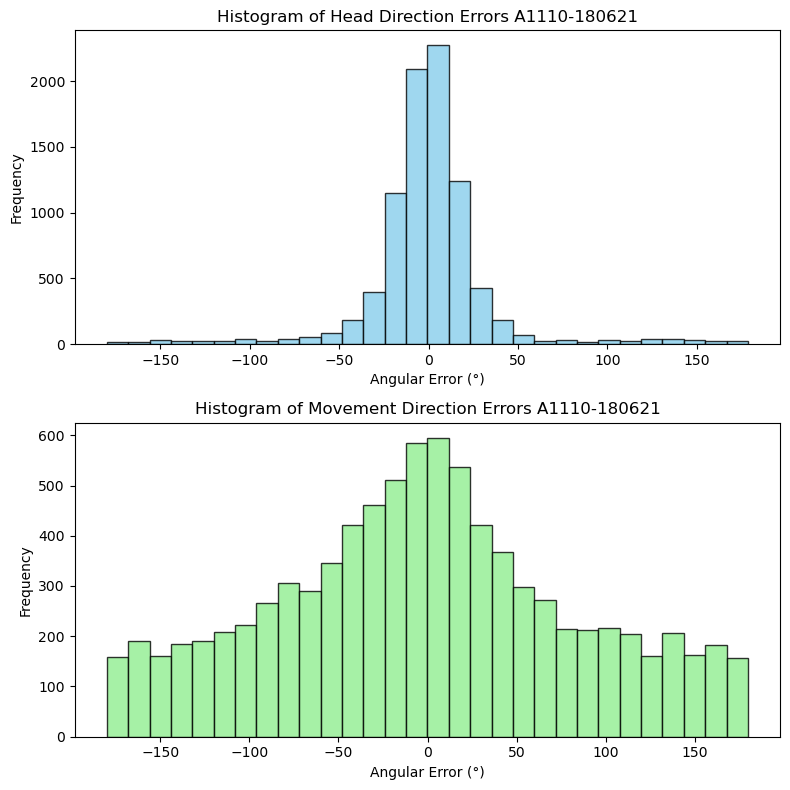

In [7]:
fig, axs = plt.subplots(2, 1, figsize=(8, 8))

axs[0].hist(hd_errors, bins=30, color='skyblue', edgecolor='black', alpha=0.8)
axs[0].set_title(f"Histogram of Head Direction Errors {session}")
axs[0].set_xlabel("Angular Error (°)")
axs[0].set_ylabel("Frequency")

axs[1].hist(md_errors, bins=30, color='lightgreen', edgecolor='black', alpha=0.8)
axs[1].set_title(f"Histogram of Movement Direction Errors {session}")
axs[1].set_xlabel("Angular Error (°)")
axs[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

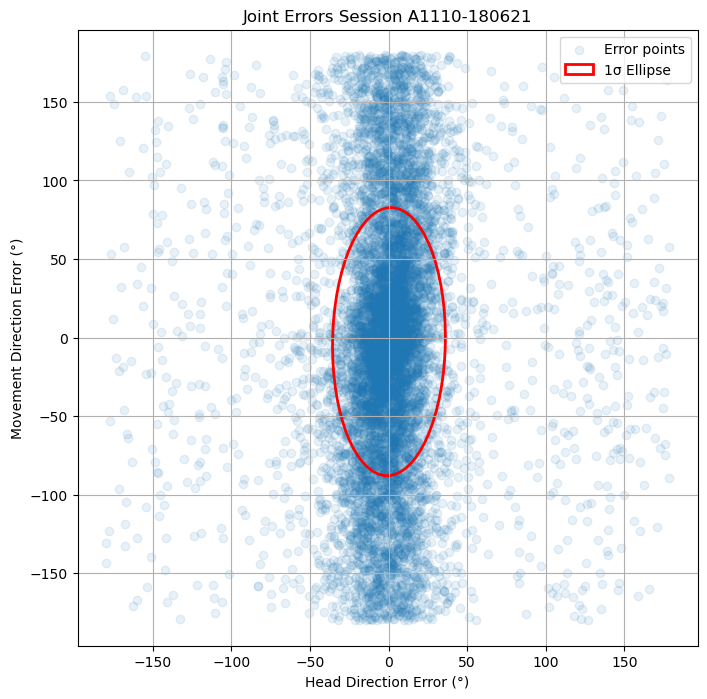

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# Joint decoding: Combine errors into a 2D array
nan_mask = np.isnan(hd_errors)
hd_errors = hd_errors[~nan_mask]
md_errors = md_errors[~nan_mask]

errors = np.vstack((hd_errors, md_errors))

# Create a scatter plot of the centered errors
plt.figure(figsize=(8, 8))
plt.scatter(hd_errors, md_errors, alpha=0.1, label='Error points')
plt.xlabel('Head Direction Error (°)')
plt.ylabel('Movement Direction Error (°)')
plt.title(f'Joint Errors Session {session}')

# Fit a 2D Gaussian: compute mean and covariance of the errors
mean = np.nanmean(errors, axis=1)  # Mean vector of [HD_error, MD_error]
#import numpy.ma as ma
#cov = ma.cov(ma.masked_invalid(errors), rowvar=False)
cov = np.cov(errors)            # Covariance matrix

# Eigen-decomposition to get the ellipse parameters
eigvals, eigvecs = np.linalg.eig(cov)
# Compute the angle of the ellipse (in degrees)
angle = np.degrees(np.arctan2(eigvecs[1, 0], eigvecs[0, 0]))
# For a 1-sigma ellipse, width and height are 2*sqrt(eigenvalues)
width, height = 2 * np.sqrt(eigvals[0]), 2 * np.sqrt(eigvals[1])

# Plot the 1-sigma ellipse representing the 2D Gaussian fit
ellipse = patches.Ellipse(xy=mean, width=width, height=height, angle=angle,
                          edgecolor='red', fc='None', lw=2, label='1σ Ellipse')
plt.gca().add_patch(ellipse)

plt.legend()
plt.grid(True)
plt.axis('equal')
plt.show()


In [ ]:
# so we wanna see if you condition on hd is there residual information about MD
# we might wanna condition on one HD error and then see what you can do about md
# take some bin slices
# the idea being if you destroyed MD selectivity truly would it look the same as above still
# just try changing the movement direction to a uniform distribution between 0 and 360